# FuelNet — Exploratory Data Analysis (EDA)
Dataset: `data/Fuel_Consumption_2000-2022.csv` (Canadian NRCan 2000-2022). This notebook prints exact columns, renames to snake_case, and inspects data quality.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib, re
plt.style.use('dark_background')
sns.set_theme(style='whitegrid')
csv_path = pathlib.Path('../data/Fuel_Consumption_2000-2022.csv')
if not csv_path.exists():
    csv_path = pathlib.Path('data/Fuel_Consumption_2000-2022.csv')
if not csv_path.exists():
    csv_path = pathlib.Path(r'E:\fuelnet\data\Fuel_Consumption_2000-2022.csv')
print('CSV path:', csv_path.resolve())
print('Exists:', csv_path.exists())

CSV path: E:\fuelnet\data\Fuel_Consumption_2000-2022.csv
Exists: True


In [2]:
# 0 — Exact column names before cleaning
df_raw = pd.read_csv(csv_path, nrows=0)
print('Exact columns:', df_raw.columns.tolist())
for c in df_raw.columns:
    print(repr(c))
df = pd.read_csv(csv_path)
print('\nShape raw:', df.shape)

Exact columns: ['YEAR', 'MAKE', 'MODEL', 'VEHICLE CLASS', 'ENGINE SIZE', 'CYLINDERS', 'TRANSMISSION', 'FUEL', 'FUEL CONSUMPTION', 'HWY (L/100 km)', 'COMB (L/100 km)', 'COMB (mpg)', 'EMISSIONS']
'YEAR'
'MAKE'
'MODEL'
'VEHICLE CLASS'
'ENGINE SIZE'
'CYLINDERS'
'TRANSMISSION'
'FUEL'
'FUEL CONSUMPTION'
'HWY (L/100 km)'
'COMB (L/100 km)'
'COMB (mpg)'
'EMISSIONS'

Shape raw: (22556, 13)


In [3]:
# 0b — Rename to clean snake_case (use renamed columns everywhere from now on)
rename_map = {
    'YEAR': 'year',
    'MAKE': 'make',
    'MODEL': 'model',
    'VEHICLE CLASS': 'vehicle_class',
    'ENGINE SIZE': 'engine_size_l',
    'CYLINDERS': 'cylinders',
    'TRANSMISSION': 'transmission',
    'FUEL': 'fuel_type',
    'FUEL CONSUMPTION': 'fuel_city_l_100km',  # CITY - 9.2 L/100km in sample row
    'HWY (L/100 km)': 'fuel_hwy_l_100km',
    'COMB (L/100 km)': 'fuel_comb_l_100km',
    'COMB (mpg)': 'fuel_comb_mpg',
    'EMISSIONS': 'co2_g_km',
}
df.rename(columns=rename_map, inplace=True)
print('Renamed columns:', df.columns.tolist())
# verify all renamed
expected = ['year','make','model','vehicle_class','engine_size_l','cylinders','transmission','fuel_type','fuel_city_l_100km','fuel_hwy_l_100km','fuel_comb_l_100km','fuel_comb_mpg','co2_g_km']
assert list(df.columns) == expected, 'Rename mismatch!'
print('Rename OK — 13 columns mapped to snake_case')

Renamed columns: ['year', 'make', 'model', 'vehicle_class', 'engine_size_l', 'cylinders', 'transmission', 'fuel_type', 'fuel_city_l_100km', 'fuel_hwy_l_100km', 'fuel_comb_l_100km', 'fuel_comb_mpg', 'co2_g_km']
Rename OK — 13 columns mapped to snake_case


In [4]:
# 1 — first 10 rows, shape, column info
print('Shape:', df.shape)
display(df.head(10))
print(df.info())
print(df.describe().round(2).to_string())

Shape: (22556, 13)


,year,make,model,vehicle_class,engine_size_l,cylinders,transmission,fuel_type,fuel_city_l_100km,fuel_hwy_l_100km,fuel_comb_l_100km,fuel_comb_mpg,co2_g_km
0,2000,ACURA,1.6EL,COMPACT,1.6,4,A4,X,9.2,6.7,8.1,35,186
1,2000,ACURA,1.6EL,COMPACT,1.6,4,M5,X,8.5,6.5,7.6,37,175
2,2000,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,12.2,7.4,10.0,28,230
3,2000,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,13.4,9.2,11.5,25,264
4,2000,ACURA,INTEGRA,SUBCOMPACT,1.8,4,A4,X,10.0,7.0,8.6,33,198
5,2000,ACURA,INTEGRA,SUBCOMPACT,1.8,4,M5,X,9.3,6.8,8.2,34,189
6,2000,ACURA,INTEGRA GSR/TYPE R,SUBCOMPACT,1.8,4,M5,Z,9.4,7.0,8.3,34,191
7,2000,ACURA,NSX,SUBCOMPACT,3.0,6,AS4,Z,13.6,9.2,11.6,24,267
8,2000,ACURA,NSX,SUBCOMPACT,3.2,6,M6,Z,13.8,9.1,11.7,24,269
9,2000,AUDI,A4,COMPACT,1.8,4,A5,Z,11.4,7.2,9.5,30,218


<class 'pandas.DataFrame'>
RangeIndex: 22556 entries, 0 to 22555
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               22556 non-null  int64  
 1   make               22556 non-null  str    
 2   model              22556 non-null  str    
 3   vehicle_class      22556 non-null  str    
 4   engine_size_l      22556 non-null  float64
 5   cylinders          22556 non-null  int64  
 6   transmission       22556 non-null  str    
 7   fuel_type          22556 non-null  str    
 8   fuel_city_l_100km  22556 non-null  float64
 9   fuel_hwy_l_100km   22556 non-null  float64
 10  fuel_comb_l_100km  22556 non-null  float64
 11  fuel_comb_mpg      22556 non-null  int64  
 12  co2_g_km           22556 non-null  int64  
dtypes: float64(4), int64(4), str(5)
memory usage: 2.2 MB
None
           year  engine_size_l  cylinders  fuel_city_l_100km  fuel_hwy_l_100km  fuel_comb_l_100km  fuel_comb_mpg  co2_g

In [5]:
# 2 — unique values for categoricals
for col in ['make','model','vehicle_class','transmission','fuel_type']:
    uniq = sorted(df[col].dropna().unique().tolist())
    print(f"{col}: {len(uniq)} uniques")
    print(uniq[:50])
    if len(uniq) > 50:
        print(' ... truncated, showing first 50')
    print()
print('Full vehicle_class uniques:')
print(sorted(df['vehicle_class'].unique().tolist()))
print('\nFull transmission uniques:')
print(sorted(df['transmission'].unique().tolist()))
print('\nFull fuel_type uniques:')
print(sorted(df['fuel_type'].unique().tolist()))

make: 87 uniques
['ACURA', 'ALFA ROMEO', 'ASTON MARTIN', 'AUDI', 'Acura', 'Alfa Romeo', 'Aston Martin', 'Audi', 'BENTLEY', 'BMW', 'BUGATTI', 'BUICK', 'Bentley', 'Bugatti', 'Buick', 'CADILLAC', 'CHEVROLET', 'CHRYSLER', 'Cadillac', 'Chevrolet', 'Chrysler', 'DAEWOO', 'DODGE', 'Dodge', 'FERRARI', 'FIAT', 'FORD', 'Ford', 'GENESIS', 'GMC', 'Genesis', 'HONDA', 'HUMMER', 'HYUNDAI', 'Honda', 'Hyundai', 'INFINITI', 'ISUZU', 'Infiniti', 'JAGUAR', 'JEEP', 'Jaguar', 'Jeep', 'KIA', 'Kia', 'LAMBORGHINI', 'LAND ROVER', 'LEXUS', 'LINCOLN', 'Lamborghini']
 ... truncated, showing first 50

model: 4242 uniques
['1 SERIES M COUPE', '1.6EL', '1.7EL', '124 SPIDER', '124 Spider', '128i CABRIOLET', '128i COUPE', '135i CABRIOLET', '135i COUPE', '1500', '1500 (FuelSaver MDS)', '1500 (MDS)', '1500 4X4', '1500 4X4 (FuelSaver MDS)', '1500 4X4 (MDS)', '1500 4X4 DIESEL', '1500 4X4 ECODIESEL', '1500 4X4 EcoDiesel', '1500 4X4 FFV', '1500 4X4 TRX', '1500 4X4 eTorque', '1500 Classic', '1500 Classic 4X4', '1500 Classic 4X

In [6]:
# 3 — missing values per column
print(df.isnull().sum().to_string())
print('Total missing:', int(df.isnull().sum().sum()))
# also check empty strings
for col in df.select_dtypes(include='object').columns:
    empty = (df[col].astype(str).str.strip() == '').sum()
    print(f"empty strings in {col}: {empty}")

year                 0
make                 0
model                0
vehicle_class        0
engine_size_l        0
cylinders            0
transmission         0
fuel_type            0
fuel_city_l_100km    0
fuel_hwy_l_100km     0
fuel_comb_l_100km    0
fuel_comb_mpg        0
co2_g_km             0
Total missing: 0
empty strings in make: 0
empty strings in model: 0
empty strings in vehicle_class: 0
empty strings in transmission: 0
empty strings in fuel_type: 0


C:\Users\dnaga\AppData\Local\Temp\ipykernel_23672\4023701995.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


C:\Users\dnaga\AppData\Local\Temp\ipykernel_23672\234758990.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='cylinders', data=df, ax=axes[0,1], palette='viridis', order=sorted(df['cylinders'].unique()))


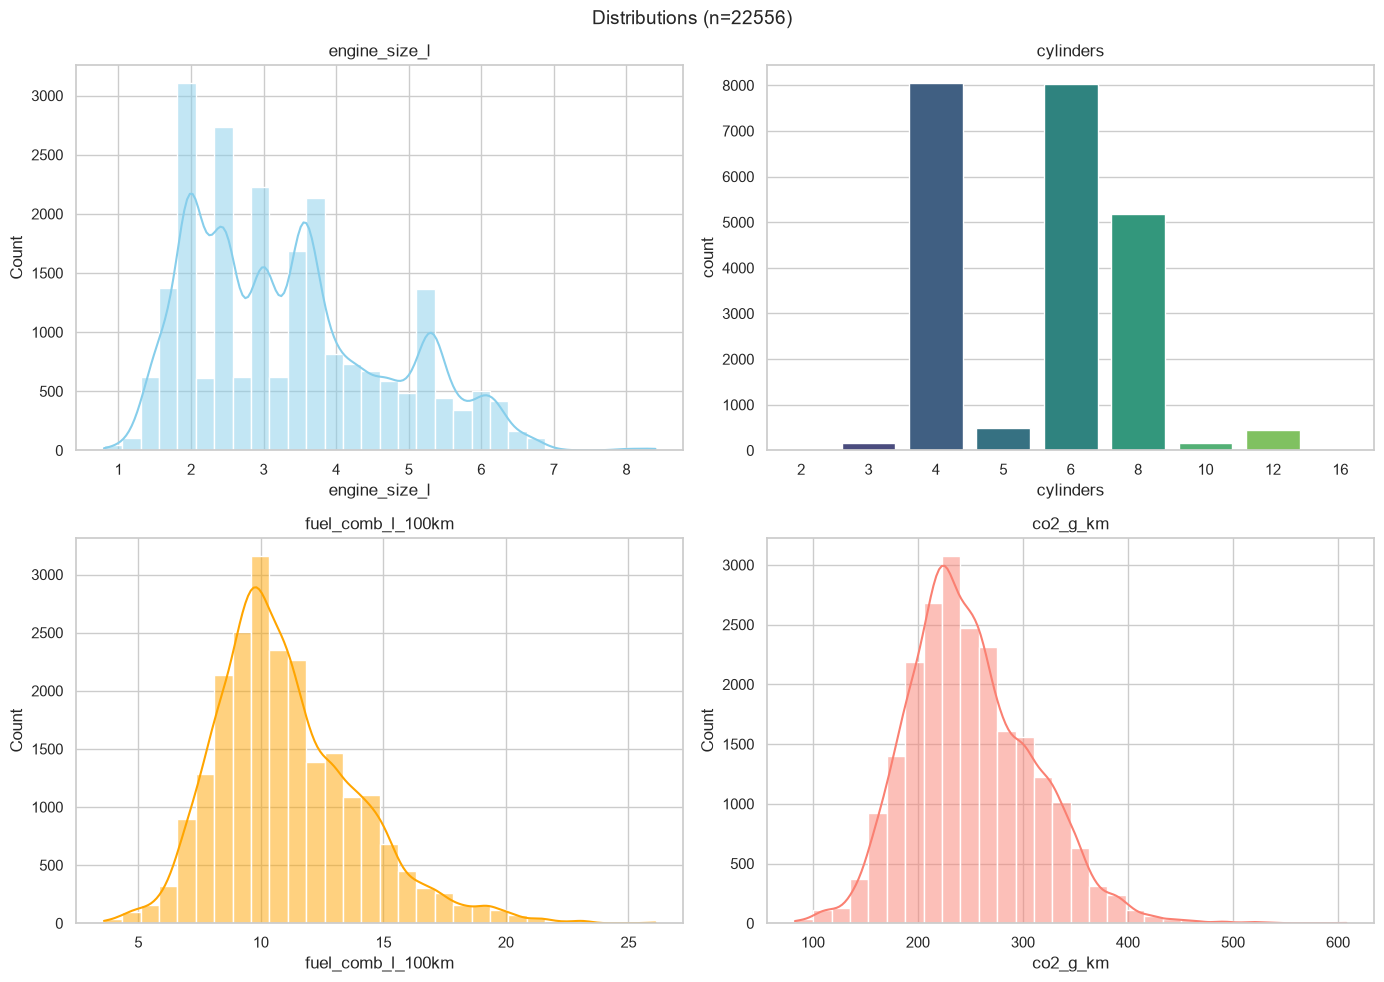

count    22556.000000
mean         3.356646
std          1.335425
min          0.800000
25%          2.300000
50%          3.000000
75%          4.200000
max          8.400000

count    22556.000000
mean         5.854141
std          1.819597
min          2.000000
25%          4.000000
50%          6.000000
75%          8.000000
max         16.000000

count    22556.000000
mean        11.034341
std          2.910920
min          3.600000
25%          9.100000
50%         10.600000
75%         12.700000
max         26.100000

count    22556.000000
mean       250.068452
std         59.355276
min         83.000000
25%        209.000000
50%        243.000000
75%        288.000000
max        608.000000



In [7]:
# 4 — Distributions of engine_size_l, cylinders, fuel_comb, co2
fig, axes = plt.subplots(2,2, figsize=(14,10))
fig.suptitle('Distributions (n=22556)', fontsize=14)
sns.histplot(df['engine_size_l'], bins=30, kde=True, ax=axes[0,0], color='skyblue')
axes[0,0].set_title('engine_size_l')
sns.countplot(x='cylinders', data=df, ax=axes[0,1], palette='viridis', order=sorted(df['cylinders'].unique()))
axes[0,1].set_title('cylinders')
sns.histplot(df['fuel_comb_l_100km'], bins=30, kde=True, ax=axes[1,0], color='orange')
axes[1,0].set_title('fuel_comb_l_100km')
sns.histplot(df['co2_g_km'], bins=30, kde=True, ax=axes[1,1], color='salmon')
axes[1,1].set_title('co2_g_km')
plt.tight_layout()
plt.show()
for col in ['engine_size_l','cylinders','fuel_comb_l_100km','co2_g_km']:
    print(df[col].describe().to_string())
    print()

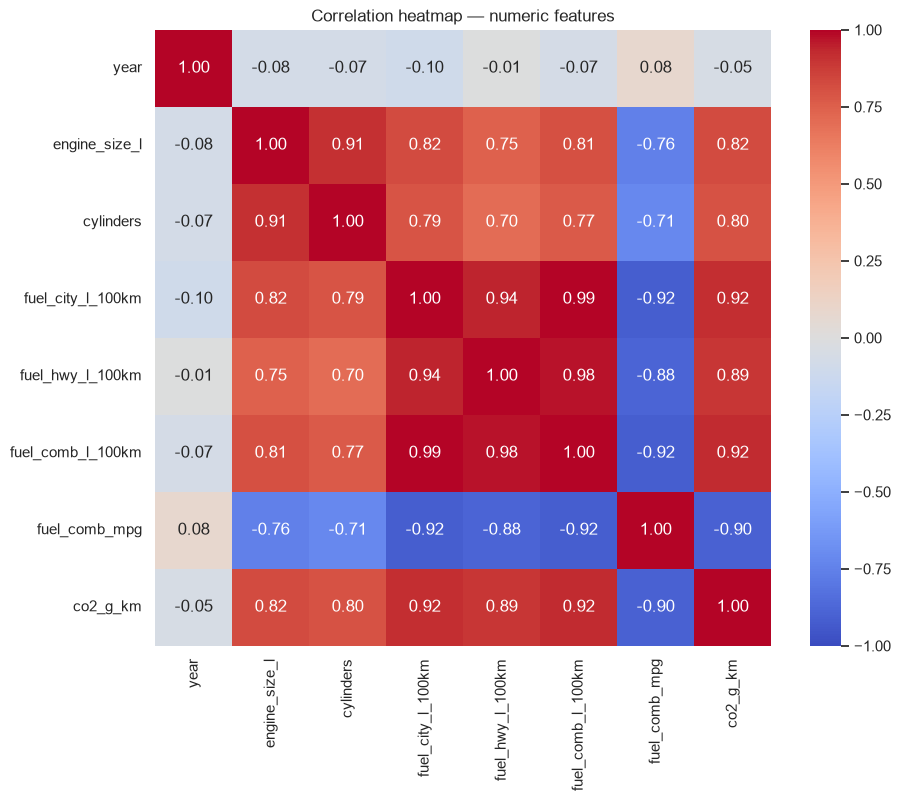

                   year  engine_size_l  cylinders  fuel_city_l_100km  fuel_hwy_l_100km  fuel_comb_l_100km  fuel_comb_mpg  co2_g_km
year               1.00          -0.08      -0.07              -0.10             -0.01              -0.07           0.08     -0.05
engine_size_l     -0.08           1.00       0.91               0.82              0.75               0.81          -0.76      0.82
cylinders         -0.07           0.91       1.00               0.79              0.70               0.77          -0.71      0.80
fuel_city_l_100km -0.10           0.82       0.79               1.00              0.94               0.99          -0.92      0.92
fuel_hwy_l_100km  -0.01           0.75       0.70               0.94              1.00               0.98          -0.88      0.89
fuel_comb_l_100km -0.07           0.81       0.77               0.99              0.98               1.00          -0.92      0.92
fuel_comb_mpg      0.08          -0.76      -0.71              -0.92             -0

In [8]:
# 5 — Correlation heatmap between numeric features
numeric_cols = ['year','engine_size_l','cylinders','fuel_city_l_100km','fuel_hwy_l_100km','fuel_comb_l_100km','fuel_comb_mpg','co2_g_km']
corr = df[numeric_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation heatmap — numeric features')
plt.show()
print(corr.round(2).to_string())

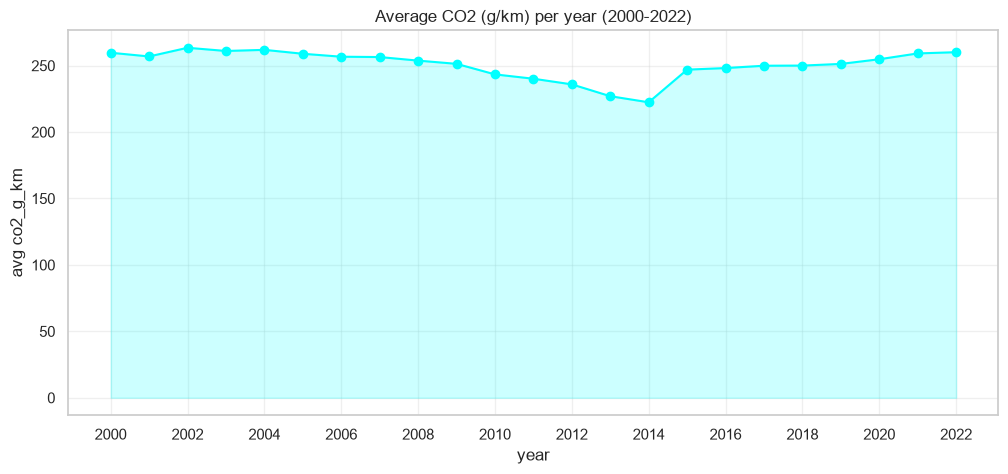

 year   co2_g_km
 2000 259.696401
 2001 256.901325
 2002 263.435135
 2003 261.028049
 2004 261.871938
 2005 258.931305
 2006 256.706612
 2007 256.453500
 2008 253.775718
 2009 251.343407
 2010 243.408423
 2011 240.134758
 2012 235.895467
 2013 226.987713
 2014 222.405769
 2015 246.970848
 2016 248.163964
 2017 249.924386
 2018 250.037858
 2019 251.279356
 2020 254.801653
 2021 259.180659
 2022 260.110995

Trend: min 222.40576923076924 at year 2014
Max 263.4351351351351 at year 2002


In [9]:
# 6 — Average co2_g_km per year (2000-2022) line chart
avg_co2 = df.groupby('year')['co2_g_km'].mean().reset_index()
plt.figure(figsize=(12,5))
plt.plot(avg_co2['year'], avg_co2['co2_g_km'], marker='o', color='cyan')
plt.fill_between(avg_co2['year'], avg_co2['co2_g_km'], alpha=0.2, color='cyan')
plt.title('Average CO2 (g/km) per year (2000-2022)')
plt.xlabel('year')
plt.ylabel('avg co2_g_km')
plt.grid(True, alpha=0.3)
plt.xticks(range(2000,2023,2))
plt.show()
print(avg_co2.to_string(index=False))
print()
print('Trend: min', avg_co2['co2_g_km'].min(), 'at year', int(avg_co2.loc[avg_co2['co2_g_km'].idxmin(),'year']))
print('Max', avg_co2['co2_g_km'].max(), 'at year', int(avg_co2.loc[avg_co2['co2_g_km'].idxmax(),'year']))

In [10]:
# 7 — Unique make+model combinations + inconsistent naming examples
df['make_model'] = df['make'] + ' ' + df['model']
n_combos = df['make_model'].nunique()
print(f"Unique make+model combinations: {n_combos} (from {len(df)} rows)")
print(f"Unique makes: {df['make'].nunique()}, unique models: {df['model'].nunique()}")
print('\nExamples of inconsistent naming — vehicle_class casing:')
print(sorted(df['vehicle_class'].unique().tolist()))
print('\nExamples where same semantic class has different spellings:')
for pat in ['COMPACT','PICKUP','SUV','VAN','STATION','SPECIAL']:
    vals = [v for v in df['vehicle_class'].unique() if pat.lower() in v.lower()]
    print(pat, '->', vals)
print('\nModel naming inconsistencies — F-150 family:')
f150_like = sorted([m for m in df['model'].unique() if 'F-150' in m or 'F150' in m])
print(f150_like[:30])
print('Total F-like models:', len(f150_like))
print('\nAnother example — "TACOMA" vs "Tacoma" casing is not present but check lower/upper:')
print(df['model'].value_counts().head(20).to_string())
print('\nCheck if make/model have leading/trailing whitespace or hyphen variations:')
# show models with hyphens vs without for same base
print(df[df['model'].str.contains('150', na=False)]['model'].value_counts().head(20).to_string())
print('\nDuplicate combos across years:')
combo_counts = df['make_model'].value_counts()
print('Top 20 most frequent make_model:')
print(combo_counts.head(20).to_string())

Unique make+model combinations: 4417 (from 22556 rows)
Unique makes: 87, unique models: 4242

Examples of inconsistent naming — vehicle_class casing:
['COMPACT', 'Compact', 'FULL-SIZE', 'Full-size', 'MID-SIZE', 'MINICOMPACT', 'MINIVAN', 'Mid-size', 'Minicompact', 'Minivan', 'PICKUP TRUCK - SMALL', 'PICKUP TRUCK - STANDARD', 'Pickup truck: Small', 'Pickup truck: Standard', 'SPECIAL PURPOSE VEHICLE', 'STATION WAGON - MID-SIZE', 'STATION WAGON - SMALL', 'SUBCOMPACT', 'SUV', 'SUV - SMALL', 'SUV - STANDARD', 'SUV: Small', 'SUV: Standard', 'Special purpose vehicle', 'Station wagon: Mid-size', 'Station wagon: Small', 'Subcompact', 'TWO-SEATER', 'Two-seater', 'VAN - CARGO', 'VAN - PASSENGER', 'Van: Passenger']

Examples where same semantic class has different spellings:
COMPACT -> ['COMPACT', 'SUBCOMPACT', 'MINICOMPACT', 'Compact', 'Minicompact', 'Subcompact']
PICKUP -> ['PICKUP TRUCK - STANDARD', 'PICKUP TRUCK - SMALL', 'Pickup truck: Small', 'Pickup truck: Standard']
SUV -> ['SUV', 'SUV - ST

## Summary placeholder — fill after running
Rows, missing, quality issues, CO2 trend will be printed here.